# 03 · Generative models (Phase 2, RQ1)
Four models of increasing complexity for count vectors **x** (D categories, N = 1000 reads per sample):

| | model | idea | parameters |
|---|---|---|---|
| M0 | multinomial | one probability vector **p** for everybody | D − 1 |
| M1 | Dirichlet-multinomial (DM) | each sample has its own **p**ᵢ ~ Dirichlet(**α**) → overdispersion | D |
| M2 | DM regression | log αᵢⱼ = bⱼ + **z**ᵢ·**β**ⱼ: covariates shift the mean composition | D + K·q |
| M3 | logistic-normal multinomial (LNM) | ALR(**p**ᵢ) ~ Normal(**μ**, **Σ**): overdispersion *and* correlations between taxa | (D−1) + (D−1)D/2, shrunk |

Comparison: **held-out log-likelihood per sample** from 5-fold cross-validation (main criterion), AIC/BIC where valid,
likelihood-ratio test for the nested pair M1 ⊂ M2. Uncertainty of parameters: non-parametric bootstrap over samples.

**Resolution (decision taken with the user).** M3 has no closed-form likelihood. It is approximated by a Laplace
(saddle-point) approximation, checked by importance sampling. With all 114 categories the check fails (section 2), so all models
are compared on the **20 most abundant taxa + `Other` + `Unassigned` (D = 22)**. M0 and M1 are also compared at full resolution.

In [1]:
import sys, pathlib, time, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mt
from scipy import stats
from sklearn.model_selection import KFold
from src.config import SEED, PROCESSED, FIGURES, READS
from src.plotstyle import set_style, PALETTE
from src.models import (fit_multinomial, loglik_multinomial, fit_dm, loglik_dm, dm_moments, fit_dm_reg, loglik_dm_reg,
                        fit_lnm, loglik_lnm, loglik_lnm_is)
set_style()
rng = np.random.default_rng([SEED, 3])          # child generator for this notebook
Xf = pd.read_csv(PROCESSED / "counts_filtered.csv", index_col=0); Xf.index = Xf.index.astype(str)
meta = pd.read_csv(PROCESSED / "metadata.csv", index_col=0); meta.index = meta.index.astype(str)
K_TOP = 20

## 1. Analysis matrix: top 20 taxa + Other + Unassigned

In [2]:
taxa = [c for c in Xf.columns if c not in ("Other", "Unassigned")]
order = Xf[taxa].mean().sort_values(ascending=False).index
def aggregate_top(K):
    top = list(order[:K]); rest = [c for c in Xf.columns if c not in top + ["Unassigned"]]
    A = pd.concat([Xf[top], Xf[rest].sum(axis=1).rename("Other"), Xf["Unassigned"]], axis=1)
    ref = (A > 0).mean().idxmax()                       # ALR reference = most prevalent category, placed LAST
    return A[[c for c in A.columns if c != ref] + [ref]]
X22 = aggregate_top(K_TOP)
assert (X22.sum(axis=1) == READS).all()
X22.to_csv(PROCESSED / "counts_top20.csv")
cols = list(X22.columns); X = X22.values.astype(float); n, D = X.shape
print(f"D = {D} categories; ALR reference = '{cols[-1]}' (present in {(X22[cols[-1]] > 0).mean():.1%} of samples)")
print(f"share of reads in the 20 named taxa: {X22.iloc[:, :K_TOP].values.sum() / X.sum():.1%}; zeros: {(X == 0).mean():.2f}")

D = 22 categories; ALR reference = 'Other' (present in 99.6% of samples)
share of reads in the 20 named taxa: 78.7%; zeros: 0.41


## 2. Why not all 114 categories? Accuracy of the Laplace approximation
For M3, log p(**x**) = log ∫ Mult(**x** | softmax **z**) N(**z** | **μ**, **Σ**) d**z** has no closed form.
The **Laplace approximation** replaces the integrand by a Gaussian around its maximum (second-order Taylor expansion of the log, as in
the saddle-point method). It is checked against **importance sampling** (IS): draw **z** from that Gaussian (widened by 1.2) and
average the weights p(**x**, **z**)/q(**z**). IS is reliable only if the effective sample size (ESS) of the weights is large.

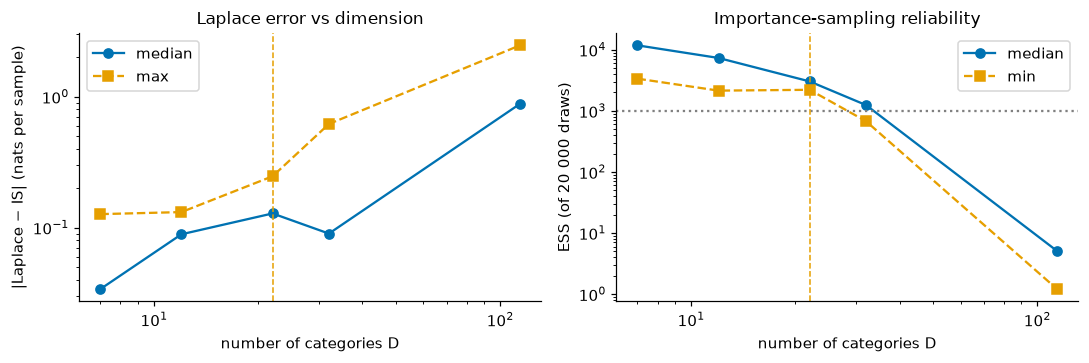

,D,median |Laplace-IS|,max |Laplace-IS|,median ESS,min ESS
0,7,0.034,0.127,11805.775,3362.520
1,12,0.089,0.131,7339.136,2142.903
2,22,0.128,0.247,3031.249,2210.365
3,32,0.090,0.618,1243.941,676.967
4,114,0.881,2.464,5.084,1.209


In [3]:
rows = []
for K in [5, 10, 20, 30, len(taxa)]:
    A = aggregate_top(K).values.astype(float)
    mu, S, _ = fit_lnm(A, shrink=0.2)
    la = loglik_lnm(A, mu, S)
    idx = rng.choice(len(A), 15, replace=False)
    res = [loglik_lnm_is(A[i], mu, S, 20000, rng) for i in idx]
    err = np.abs(la[idx] - np.array([r[0] for r in res])); ess = np.array([r[1] for r in res])
    rows.append({"D": A.shape[1], "median |Laplace-IS|": np.median(err), "max |Laplace-IS|": err.max(),
                 "median ESS": np.median(ess), "min ESS": ess.min()})
lap = pd.DataFrame(rows); lap.to_csv(PROCESSED / "model_laplace_check.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(lap["D"], lap["median |Laplace-IS|"], "o-", label="median"); ax[0].plot(lap["D"], lap["max |Laplace-IS|"], "s--", label="max")
ax[0].set(xscale="log", yscale="log", xlabel="number of categories D", ylabel="|Laplace − IS| (nats per sample)", title="Laplace error vs dimension"); ax[0].legend()
ax[1].plot(lap["D"], lap["median ESS"], "o-", label="median"); ax[1].plot(lap["D"], lap["min ESS"], "s--", label="min")
ax[1].axhline(1000, color="grey", ls=":"); ax[1].set(xscale="log", yscale="log", xlabel="number of categories D", ylabel="ESS (of 20 000 draws)", title="Importance-sampling reliability"); ax[1].legend()
for a in ax: a.axvline(22, color=PALETTE[1], ls="--", lw=1)
fig.tight_layout(); fig.savefig(FIGURES / "model_laplace_check.png"); plt.show()
lap.round(3)

## 3. Fit on all samples: in-sample fit, AIC, BIC
AIC = 2k − 2ℓ̂, BIC = k ln n − 2ℓ̂ (k parameters, ℓ̂ maximised log-likelihood). Both need an exact maximum-likelihood fit,
so they are **not reported for M3** (shrinkage penalises the fit and its likelihood is approximate).

In [4]:
p0 = fit_multinomial(X); alpha = fit_dm(X)
A_prec = alpha.sum(); rho = 1 / (1 + A_prec)
ll0, ll1 = loglik_multinomial(X, p0).sum(), loglik_dm(X, alpha).sum()
print(f"M1 precision A = sum(alpha) = {A_prec:.2f}; overdispersion rho = 1/(1+A) = {rho:.3f}")
print(f"-> DM variance = multinomial variance x (1 + (N-1) rho) = x {1 + (READS-1)*rho:.1f}")
_, v_dm = dm_moments(alpha, READS)
emp_ratio = X.var(0, ddof=1) / (X.mean(0) * (1 - X.mean(0) / READS))
print(f"empirical variance / multinomial variance per category: median {np.median(emp_ratio):.1f} (range {emp_ratio.min():.1f}-{emp_ratio.max():.1f})")
def ic(ll, k): return {"k": k, "logL": ll, "AIC": 2*k - 2*ll, "BIC": k*np.log(n) - 2*ll}
ic_tab = pd.DataFrame({"M0 multinomial": ic(ll0, D - 1), "M1 DM": ic(ll1, D)}).T
ic_tab.round(1)

M1 precision A = sum(alpha) = 4.82; overdispersion rho = 1/(1+A) = 0.172
-> DM variance = multinomial variance x (1 + (N-1) rho) = x 172.6
empirical variance / multinomial variance per category: median 257.0 (range 34.1-821.3)


,k,logL,AIC,BIC
M0 multinomial,21.0,-286107.0,572256.0,572331.8
M1 DM,22.0,-17803.3,35650.5,35729.9


## 4. Cross-validation (main model comparison)
5-fold CV, fixed seed. Each model is fitted on 4/5 of the samples and scored on the held-out 1/5 by the **log-probability it gives
to the unseen samples**. Higher is better. Unlike in-sample fit, this penalises over-fitting automatically. Held-out M3 values
use importance sampling (10 000 draws per sample; ESS recorded), so they are essentially exact.
Uncertainty: standard error of the mean over samples; differences between models are **paired** (same samples).
The M3 shrinkage λ is chosen on the same folds (picking the best of 8 values gives a small optimistic bias, stated in the report).

In [5]:
LAMBDAS = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7]
folds = list(KFold(5, shuffle=True, random_state=SEED).split(X))
cv = {m: np.full(n, np.nan) for m in ["M0", "M1"] + [f"M3 λ={l}" for l in LAMBDAS]}
cv_lap = {l: np.full(n, np.nan) for l in LAMBDAS}; ess_min = np.inf
t0 = time.time()
for tr, te in folds:
    cv["M0"][te] = loglik_multinomial(X[te], fit_multinomial(X[tr]))
    cv["M1"][te] = loglik_dm(X[te], fit_dm(X[tr]))
    for l in LAMBDAS:
        mu, S, _ = fit_lnm(X[tr], shrink=l)
        cv_lap[l][te] = loglik_lnm(X[te], mu, S)
        res = [loglik_lnm_is(x, mu, S, 10000, rng) for x in X[te]]
        cv[f"M3 λ={l}"][te] = [r[0] for r in res]; ess_min = min(ess_min, min(r[1] for r in res))
print(f"CV done in {time.time()-t0:.0f}s; smallest IS effective sample size over all held-out samples: {ess_min:.0f}")
print("max |Laplace - IS| on held-out samples: %.2f nats" % max(np.abs(cv_lap[l] - cv[f'M3 λ={l}']).max() for l in LAMBDAS))

def summarise(cvd, base="M1"):
    out = []
    for m, v in cvd.items():
        d = v - cvd[base]
        out.append({"model": m, "CV logL per sample": v.mean(), "SE": v.std(ddof=1) / np.sqrt(len(v)),
                    f"diff vs {base}": d.mean(), "SE diff": d.std(ddof=1) / np.sqrt(len(d)),
                    "share of samples better than " + base: (d > 0).mean()})
    return pd.DataFrame(out).set_index("model")
cv_tab = summarise(cv); cv_tab.round(2)

CV done in 33s; smallest IS effective sample size over all held-out samples: 28
max |Laplace - IS| on held-out samples: 0.58 nats


,CV logL per sample,SE,diff vs M1,SE diff,share of samples better than M1
model,,,,,
M0,-1074.30,46.41,-1009.00,46.81,0.00
M1,-65.30,1.04,0.00,0.00,0.00
M3 λ=0.005,-58.20,0.93,7.10,0.38,0.90
M3 λ=0.01,-58.14,0.93,7.16,0.37,0.90
M3 λ=0.02,-58.08,0.93,7.22,0.35,0.90
M3 λ=0.05,-58.04,0.93,7.26,0.31,0.91
M3 λ=0.1,-58.13,0.94,7.17,0.27,0.93
M3 λ=0.2,-58.44,0.96,6.86,0.24,0.93
M3 λ=0.4,-59.15,0.98,6.15,0.22,0.94


chosen shrinkage λ = 0.05


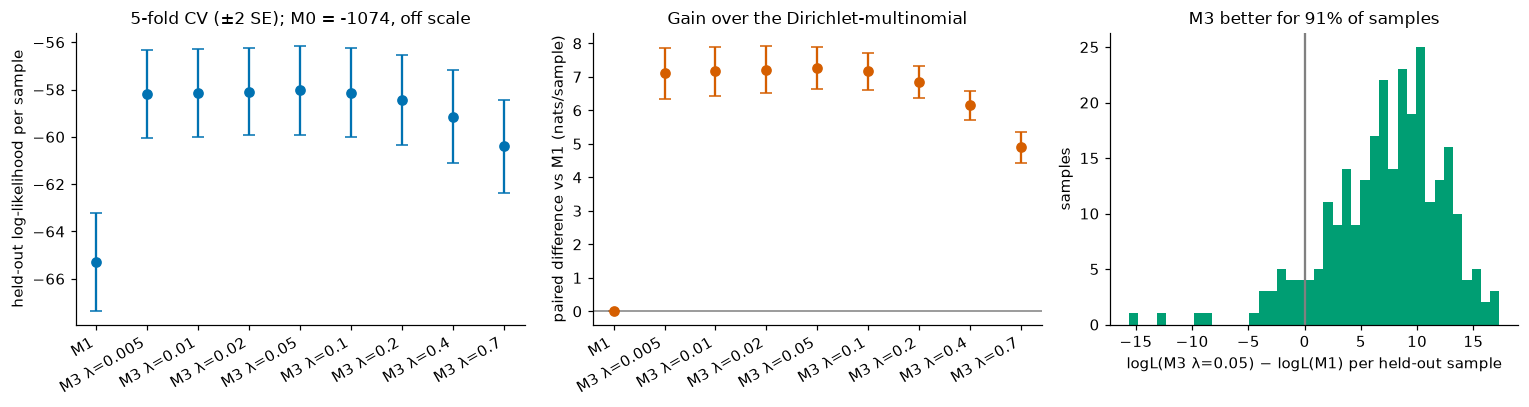

In [6]:
best = max(LAMBDAS, key=lambda l: cv[f"M3 λ={l}"].mean()); print("chosen shrinkage λ =", best)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
show = ["M1"] + [f"M3 λ={l}" for l in LAMBDAS]
ax[0].errorbar(range(len(show)), cv_tab.loc[show, "CV logL per sample"], yerr=2 * cv_tab.loc[show, "SE"], fmt="o", color=PALETTE[0], capsize=4)
ax[0].set_xticks(range(len(show))); ax[0].set_xticklabels(show, rotation=30, ha="right")
ax[0].set(ylabel="held-out log-likelihood per sample", title=f"5-fold CV (±2 SE); M0 = {cv_tab.loc['M0','CV logL per sample']:.0f}, off scale")
ax[1].errorbar(range(len(show)), cv_tab.loc[show, "diff vs M1"], yerr=2 * cv_tab.loc[show, "SE diff"], fmt="o", color=PALETTE[3], capsize=4)
ax[1].axhline(0, color="grey", lw=1); ax[1].set_xticks(range(len(show))); ax[1].set_xticklabels(show, rotation=30, ha="right")
ax[1].set(ylabel="paired difference vs M1 (nats/sample)", title="Gain over the Dirichlet-multinomial")
d = cv[f"M3 λ={best}"] - cv["M1"]
ax[2].hist(d, bins=40, color=PALETTE[2]); ax[2].axvline(0, color="grey")
ax[2].set(xlabel=f"logL(M3 λ={best}) − logL(M1) per held-out sample", ylabel="samples", title=f"M3 better for {(d>0).mean():.0%} of samples")
fig.tight_layout(); fig.savefig(FIGURES / "model_cv.png"); plt.show()

### 4b. Full resolution (114 categories): M0 vs M1 only (both likelihoods exact)

In [7]:
XF = Xf.values.astype(float); cv_full = {"M0": np.full(n, np.nan), "M1": np.full(n, np.nan)}
for tr, te in folds:
    p_tr = fit_multinomial(XF[tr])
    if (p_tr[XF[te].sum(0) > 0] == 0).any():   # a taxon unseen in training would give -inf under M0
        print("warning: unseen category in a training fold")
    cv_full["M0"][te] = loglik_multinomial(XF[te], p_tr)
    cv_full["M1"][te] = loglik_dm(XF[te], fit_dm(XF[tr]))
cv_full_tab = summarise(cv_full); print("A (precision) at full resolution: %.2f" % fit_dm(XF).sum())
cv_full_tab.round(2)

A (precision) at full resolution: 10.97


,CV logL per sample,SE,diff vs M1,SE diff,share of samples better than M1
model,,,,,
M0,-1433.92,51.32,-1266.55,52.1,0.0
M1,-167.36,4.42,0.00,0.0,0.0


## 5. M2: covariates (Dirichlet-multinomial regression)
log αᵢⱼ = bⱼ + **z**ᵢ·**β**ⱼ for the 10 most abundant taxa (βⱼ = 0 for the other 12 categories). Covariates: age (standardised),
male (0/1), outie (0/1), and in a second variant washing frequency (standardised). Missing covariates are **not imputed**: each
variant uses its complete cases and M1 is refitted on exactly the same samples for a fair comparison.

Interpretation of a coefficient: exp(βⱼ) multiplies αⱼ, i.e. the expected ratio pⱼ / pₖ to any category k without covariate
effects. Example: exp(β) = 1.5 for "male" means males have on average 1.5× more of taxon j *relative to the unaffected taxa*.

**Likelihood-ratio test** (M1 is M2 with all β = 0): LR = 2(ℓ̂_M2 − ℓ̂_M1) ~ χ² with K·q degrees of freedom under H₀ (Wilks).

In [8]:
TOP_M2 = np.arange(10)
def design(d, wash):
    Z = pd.DataFrame({"Age (per SD)": (d["Age"] - d["Age"].mean()) / d["Age"].std(), "Male": (d["Gender"] == "Male") * 1.0,
                      "Outie": (d["Navel"] == "Outie") * 1.0}, index=d.index)
    if wash: Z["Wash freq (per SD)"] = (d["Wash_Freq"] - d["Wash_Freq"].mean()) / d["Wash_Freq"].std()
    return Z
variants = {"M2a: age, sex, navel": False, "M2b: + washing frequency": True}
m2_rows, m2_fit = [], {}
for name, wash in variants.items():
    covs = ["Age", "Gender", "Navel"] + (["Wash_Freq"] if wash else [])
    d = meta[covs].dropna(); Z = design(d, wash); Xs = X22.loc[d.index].values.astype(float); ns = len(d)
    th = fit_dm_reg(Xs, Z.values, TOP_M2); a1 = fit_dm(Xs)
    l2, l1 = loglik_dm_reg(Xs, Z.values, th, TOP_M2).sum(), loglik_dm(Xs, a1).sum()
    k1, k2 = D, D + len(TOP_M2) * Z.shape[1]; LR = 2 * (l2 - l1)
    cv2, cv1 = np.full(ns, np.nan), np.full(ns, np.nan)
    for tr, te in KFold(5, shuffle=True, random_state=SEED).split(Xs):
        cv2[te] = loglik_dm_reg(Xs[te], Z.values[te], fit_dm_reg(Xs[tr], Z.values[tr], TOP_M2), TOP_M2)
        cv1[te] = loglik_dm(Xs[te], fit_dm(Xs[tr]))
    dd = cv2 - cv1
    m2_rows.append({"variant": name, "n": ns, "k M1": k1, "k M2": k2, "LR": LR, "df": k2 - k1, "LR p": stats.chi2.sf(LR, k2 - k1),
                    "ΔAIC (M2−M1)": (2*k2 - 2*l2) - (2*k1 - 2*l1), "ΔBIC (M2−M1)": (k2*np.log(ns) - 2*l2) - (k1*np.log(ns) - 2*l1),
                    "CV diff M2−M1": dd.mean(), "SE": dd.std(ddof=1) / np.sqrt(ns)})
    m2_fit[name] = (d, Z, Xs, th)
m2_tab = pd.DataFrame(m2_rows).set_index("variant"); m2_tab.round(4)

,n,k M1,k M2,LR,df,LR p,ΔAIC (M2−M1),ΔBIC (M2−M1),CV diff M2−M1,SE
variant,,,,,,,,,,
"M2a: age, sex, navel",217,22,52,82.0683,30,0.0000,-22.0683,79.3287,0.0435,0.0571
M2b: + washing frequency,132,22,62,74.1222,40,0.0008,5.8778,121.1899,-0.1180,0.1015


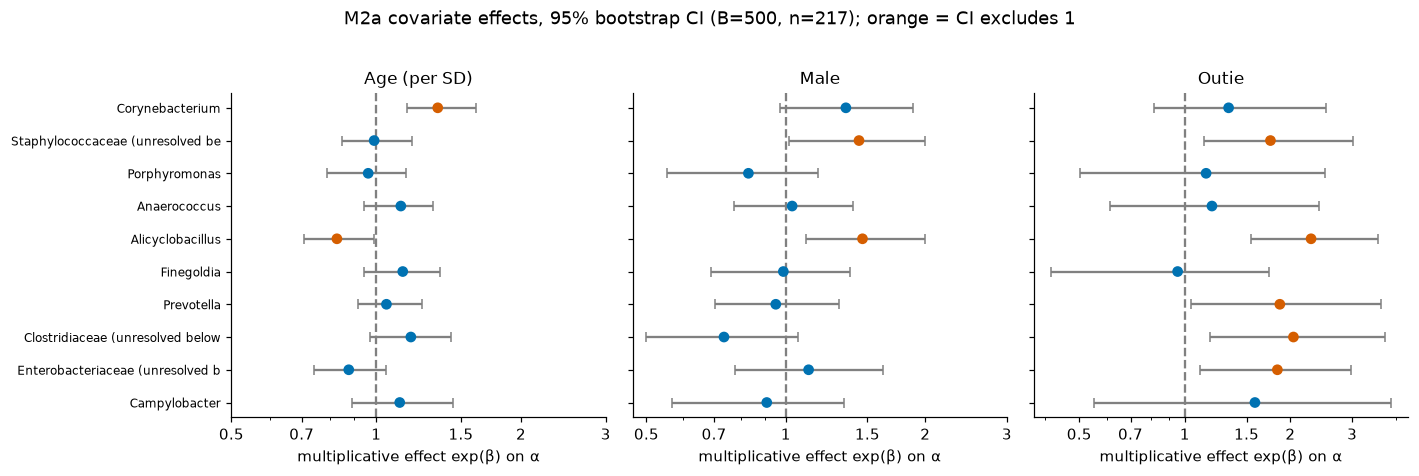

CIs excluding 1: 9 of 30 (about 1.5 expected by chance alone at 95 %)


In [9]:
# bootstrap CIs for the M2a coefficients (non-parametric: resample subjects with replacement, refit)
d, Z, Xs, th = m2_fit["M2a: age, sex, navel"]; q = Z.shape[1]; B = 500
boot = np.empty((B, q * len(TOP_M2)))
for b in range(B):
    i = rng.integers(0, len(Xs), len(Xs))
    boot[b] = fit_dm_reg(Xs[i], Z.values[i], TOP_M2, b0=th[:D])[D:]
beta = th[D:].reshape(q, -1); lo, hi = np.percentile(boot, [2.5, 97.5], axis=0); lo, hi = lo.reshape(q, -1), hi.reshape(q, -1)
names = [cols[j] for j in TOP_M2]
fig, ax = plt.subplots(1, q, figsize=(13, 4.2), sharey=True)
for c in range(q):
    y = np.arange(len(names))[::-1]
    sig = (lo[c] > 0) | (hi[c] < 0)
    ax[c].errorbar(np.exp(beta[c]), y, xerr=[np.exp(beta[c]) - np.exp(lo[c]), np.exp(hi[c]) - np.exp(beta[c])], fmt="none", ecolor="grey", capsize=3)
    ax[c].scatter(np.exp(beta[c]), y, c=[PALETTE[3] if s else PALETTE[0] for s in sig], zorder=3)
    ax[c].axvline(1, color="grey", ls="--"); ax[c].set(xscale="log", title=Z.columns[c], xlabel="multiplicative effect exp(β) on α")
    ax[c].set_xticks([0.5, 0.7, 1, 1.5, 2, 3]); ax[c].xaxis.set_major_formatter(mt.FormatStrFormatter("%g")); ax[c].xaxis.set_minor_formatter(mt.NullFormatter())
ax[0].set_yticks(np.arange(len(names))[::-1]); ax[0].set_yticklabels([s.split(";")[-1][:32] for s in names], fontsize=8)
fig.suptitle(f"M2a covariate effects, 95% bootstrap CI (B={B}, n={len(Xs)}); orange = CI excludes 1", y=1.02); fig.tight_layout()
fig.savefig(FIGURES / "model_m2_effects.png"); plt.show()
m2_coef = pd.DataFrame([{"taxon": names[j], "covariate": Z.columns[c], "exp_beta": np.exp(beta[c, j]),
                         "ci_lo": np.exp(lo[c, j]), "ci_hi": np.exp(hi[c, j])} for c in range(q) for j in range(len(names))])
m2_coef.to_csv(PROCESSED / "model_m2_coefficients.csv", index=False)
print("CIs excluding 1:", int(((lo > 0) | (hi < 0)).sum()), "of", lo.size, "(about", round(0.05 * lo.size, 1), "expected by chance alone at 95 %)")

## 6. Parameter uncertainty of M1 and M3 (bootstrap over samples)
M1: mean proportions pⱼ = αⱼ/A and the overdispersion ρ = 1/(1+A) (Var = multinomial variance × (1 + (N−1)ρ)).
M3: ALR means μⱼ and standard deviations √Σⱼⱼ (log-ratio of taxon j to the reference category).

M1: A = 4.82 (95% CI 4.40-5.35); rho = 0.172 (95% CI 0.157-0.185)


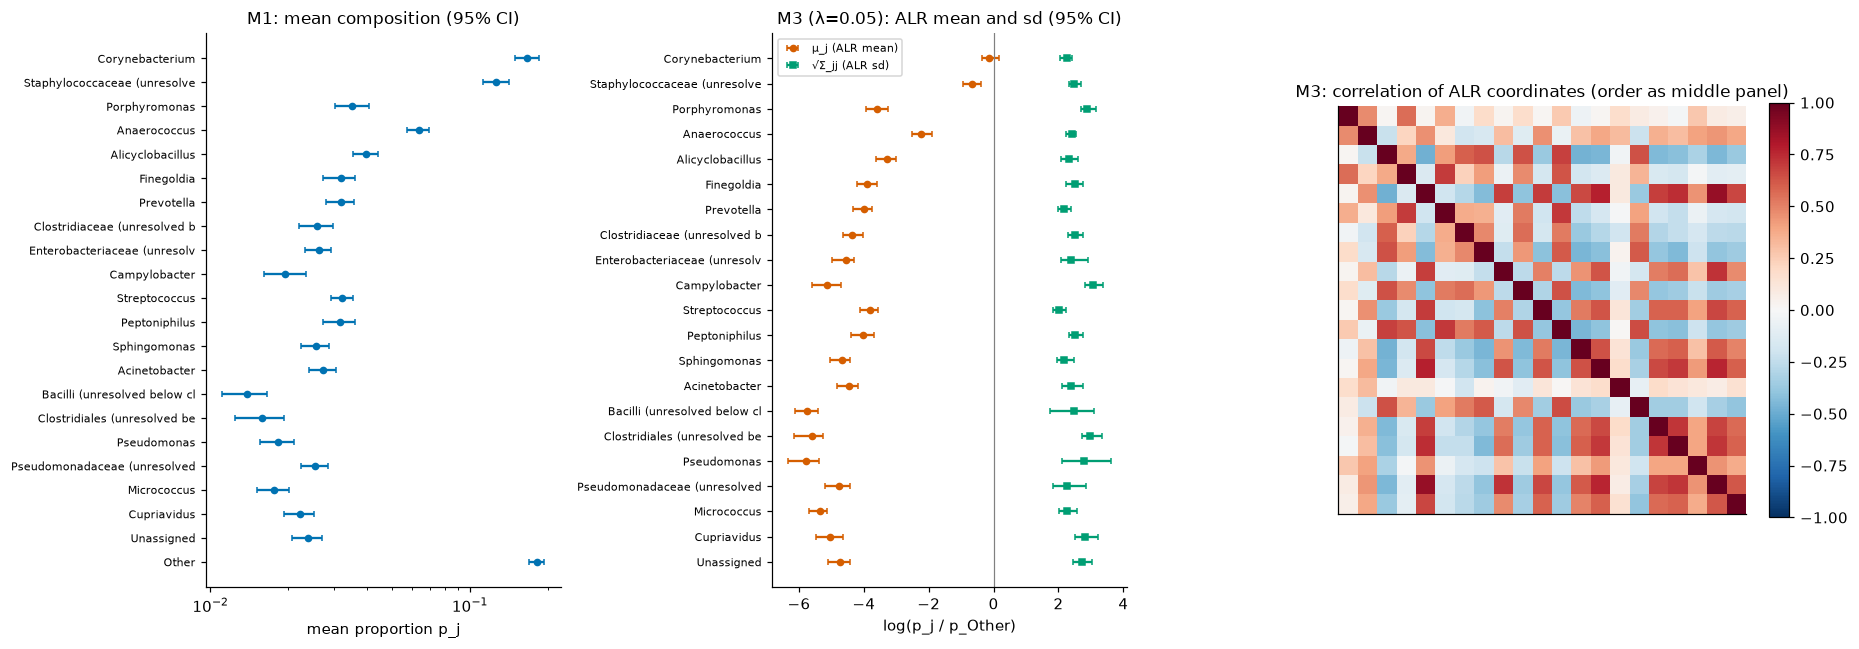

In [10]:
B1, B3 = 500, 100
bA, bp = np.empty(B1), np.empty((B1, D))
for b in range(B1):
    a = fit_dm(X[rng.integers(0, n, n)]); bA[b] = a.sum(); bp[b] = a / a.sum()
mu3, S3, trace3 = fit_lnm(X, shrink=best)
bmu, bsd = np.empty((B3, D - 1)), np.empty((B3, D - 1))
for b in range(B3):
    m_, s_, _ = fit_lnm(X[rng.integers(0, n, n)], shrink=best); bmu[b] = m_; bsd[b] = np.sqrt(np.diag(s_))
rho_ci = np.percentile(1 / (1 + bA), [2.5, 97.5])
print(f"M1: A = {A_prec:.2f} (95% CI {np.percentile(bA, 2.5):.2f}-{np.percentile(bA, 97.5):.2f}); rho = {rho:.3f} (95% CI {rho_ci[0]:.3f}-{rho_ci[1]:.3f})")

short = [c.split(";")[-1][:28] for c in cols]
fig, ax = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={"width_ratios": [1.1, 1.1, 1.4]})
y = np.arange(D)[::-1]; plo, phi = np.percentile(bp, [2.5, 97.5], axis=0); pm = alpha / A_prec
ax[0].errorbar(pm, y, xerr=[pm - plo, phi - pm], fmt="o", color=PALETTE[0], ms=4, capsize=2)
ax[0].set_yticks(y); ax[0].set_yticklabels(short, fontsize=7); ax[0].set(xscale="log", xlabel="mean proportion p_j", title="M1: mean composition (95% CI)")
y3 = np.arange(D - 1)[::-1]; mlo, mhi = np.percentile(bmu, [2.5, 97.5], axis=0); slo, shi = np.percentile(bsd, [2.5, 97.5], axis=0)
ax[1].errorbar(mu3, y3, xerr=[mu3 - mlo, mhi - mu3], fmt="o", color=PALETTE[3], ms=4, capsize=2, label="μ_j (ALR mean)")
sd3 = np.sqrt(np.diag(S3)); ax[1].errorbar(sd3, y3, xerr=[sd3 - slo, shi - sd3], fmt="s", color=PALETTE[2], ms=4, capsize=2, label="√Σ_jj (ALR sd)")
ax[1].axvline(0, color="grey", lw=.8); ax[1].set_yticks(y3); ax[1].set_yticklabels(short[:-1], fontsize=7)
ax[1].set(xlabel=f"log(p_j / p_{short[-1]})", title=f"M3 (λ={best}): ALR mean and sd (95% CI)"); ax[1].legend(fontsize=7)
Rm = S3 / np.outer(sd3, sd3); im = ax[2].imshow(Rm, cmap="RdBu_r", vmin=-1, vmax=1)
ax[2].set(title="M3: correlation of ALR coordinates (order as middle panel)", xticks=[], yticks=[]); plt.colorbar(im, ax=ax[2], fraction=.046)
fig.tight_layout(); fig.savefig(FIGURES / "model_params.png"); plt.show()

## 7. Summary table and saved parameters (used by Phases 3 and 4)

In [11]:
summary = cv_tab.copy()
summary["k"] = [D - 1, D] + [(D - 1) + (D - 1) * D // 2] * len(LAMBDAS)
summary = summary.join(ic_tab[["AIC", "BIC"]].rename(index={"M0 multinomial": "M0", "M1 DM": "M1"}))
summary.to_csv(PROCESSED / "model_comparison.csv"); cv_full_tab.to_csv(PROCESSED / "model_comparison_full_resolution.csv")
m2_tab.to_csv(PROCESSED / "model_m2_tests.csv")
d, Z, Xs, th = m2_fit["M2a: age, sex, navel"]
np.savez(PROCESSED / "model_params.npz", columns=np.array(cols), p0=p0, alpha=alpha, mu=mu3, Sigma=S3, shrink=best,
         m2a_theta=th, m2a_top=TOP_M2, m2a_covariates=np.array(Z.columns), m2a_ids=np.array(d.index),
         age_mean=d["Age"].mean(), age_sd=d["Age"].std())
summary.round(2)

,CV logL per sample,SE,diff vs M1,SE diff,share of samples better than M1,k,AIC,BIC
model,,,,,,,,
M0,-1074.30,46.41,-1009.00,46.81,0.00,21,572256.00,572331.80
M1,-65.30,1.04,0.00,0.00,0.00,22,35650.53,35729.94
M3 λ=0.005,-58.20,0.93,7.10,0.38,0.90,252,NaN,NaN
M3 λ=0.01,-58.14,0.93,7.16,0.37,0.90,252,NaN,NaN
M3 λ=0.02,-58.08,0.93,7.22,0.35,0.90,252,NaN,NaN
M3 λ=0.05,-58.04,0.93,7.26,0.31,0.91,252,NaN,NaN
M3 λ=0.1,-58.13,0.94,7.17,0.27,0.93,252,NaN,NaN
M3 λ=0.2,-58.44,0.96,6.86,0.24,0.93,252,NaN,NaN
M3 λ=0.4,-59.15,0.98,6.15,0.22,0.94,252,NaN,NaN


### Simplifications in this phase (also marked `# simplification:` in `src/models.py`)
* Models compared at D = 22 (top 20 taxa + Other + Unassigned), not 114, because M3 cannot be evaluated reliably at 114 (section 2).
* M3 fitted by an approximate EM with a Laplace E-step; covariance shrunk towards its diagonal (λ chosen by CV) instead of a low-rank model.
* M2 lets covariates act on the 10 most abundant taxa only; complete cases only; covariate effects are on α (relative abundance), not absolute abundance.
* λ for M3 chosen on the same CV folds used for the comparison (small optimistic bias).